In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from scipy.stats import binom

In [2]:
MODEL = '_imputed'

train_scores = pd.read_csv(f'../Model_scores/scores_train{MODEL}.csv')
oot1_scores = pd.read_csv(f'../Model_scores/scores_oot1{MODEL}.csv')
oot2_scores = pd.read_csv(f'../Model_scores/scores_oot2{MODEL}.csv')

pd.DataFrame({
    'rows': [len(train_scores), len(oot1_scores), len(oot2_scores)],
    'default_rate': [train_scores['y_true'].mean(), oot1_scores['y_true'].mean(), oot2_scores['y_true'].mean()],
    'mean_score': [train_scores['y_pred'].mean(), oot1_scores['y_pred'].mean(), oot2_scores['y_pred'].mean()],
}, index=['train', 'oot1', 'oot2']).round(4)

,rows,default_rate,mean_score
train,475389,0.0140,0.0140
oot1,174229,0.0170,0.0128
oot2,183730,0.0116,0.0131


In [3]:
CALIB_SET = oot1_scores
TARGET_RATE = train_scores['y_true'].mean()
PD_FLOOR = 0.0003
PD_CAP = 0.9999
TARGET_RATE

np.float64(0.013988544118606026)

In [4]:
train_scores['bins'] = pd.qcut(train_scores['y_pred'], q=10, labels=False, duplicates='drop')
score_agg = (
    train_scores.groupby('bins')
    .agg(y_true=('y_true', 'mean'),
         lower_bound=('y_pred', 'min'),
         upper_bound=('y_pred', 'max'))
    .reset_index()
)

edges = [-np.inf] + list(score_agg['upper_bound'].iloc[:-1]) + [np.inf]

def decile_pd(scores):
    bins = pd.cut(scores, bins=edges, labels=False)
    return bins.map(dict(zip(score_agg['bins'], score_agg['y_true']))).astype(float)

score_agg

,bins,y_true,lower_bound,upper_bound
0,0,0.000231,0.000257,0.001288
1,1,0.000526,0.001288,0.002009
2,2,0.000989,0.002009,0.002969
3,3,0.002230,0.002969,0.004264
4,4,0.002987,0.004264,0.005934
5,5,0.005091,0.005935,0.008073
6,6,0.007636,0.008073,0.011038
7,7,0.012137,0.011038,0.015919
8,8,0.020173,0.015920,0.027838
9,9,0.087886,0.027838,0.889552


In [5]:
iso = IsotonicRegression(y_min=PD_FLOOR, y_max=PD_CAP, out_of_bounds='clip')
iso.fit(CALIB_SET['y_pred'], CALIB_SET['y_true'])

def isotonic_pd(scores):
    return pd.Series(iso.predict(scores), index=scores.index)

pi_S = isotonic_pd(CALIB_SET['y_pred']).mean()
pi_S

np.float64(0.017030995988038727)

In [6]:
def bayes_adjust(p, pi_s, pi_t):
    p = np.asarray(p, dtype=float)
    adjusted = pi_t * (p - p * pi_s) / (pi_s - p * pi_s + p * pi_t - pi_s * pi_t)
    return np.clip(adjusted, PD_FLOOR, PD_CAP)

def calibrated_pd(scores):
    return pd.Series(bayes_adjust(isotonic_pd(scores), pi_S, TARGET_RATE), index=scores.index)

calibrated_pd(CALIB_SET['y_pred']).mean()

np.float64(0.014179777794219877)

In [7]:
for df in [train_scores, oot1_scores, oot2_scores]:
    df['pd_raw'] = df['y_pred'].clip(PD_FLOOR, PD_CAP)
    df['pd_decile'] = decile_pd(df['y_pred']).clip(PD_FLOOR, PD_CAP)
    df['pd_isotonic'] = isotonic_pd(df['y_pred'])
    df['pd_iso_bayes'] = calibrated_pd(df['y_pred'])

METHODS = ['pd_raw', 'pd_decile', 'pd_isotonic', 'pd_iso_bayes']
oot2_scores[['y_true', 'y_pred'] + METHODS].head()

,y_true,y_pred,pd_raw,pd_decile,pd_isotonic,pd_iso_bayes
0,0,0.015563,0.015563,0.012137,0.021981,0.018071
1,0,0.000778,0.000778,0.000300,0.000708,0.000580
2,0,0.004300,0.004300,0.002987,0.007189,0.005894
3,0,0.001124,0.001124,0.000300,0.000708,0.000580
4,0,0.002960,0.002960,0.000989,0.003778,0.003096


In [8]:
def summary(df, name):
    rows = []
    for m in METHODS:
        p = df[m].clip(1e-6, 1 - 1e-6)
        rows.append({
            'set': name,
            'method': m,
            'AUC': roc_auc_score(df['y_true'], p),
            'mean_PD': p.mean(),
            'actual_rate': df['y_true'].mean(),
            'Brier': brier_score_loss(df['y_true'], p),
            'LogLoss': log_loss(df['y_true'], p),
        })
    return pd.DataFrame(rows)

results = pd.concat([summary(oot1_scores, 'oot1'), summary(oot2_scores, 'oot2')])
results.round(5)

,set,method,AUC,mean_PD,actual_rate,Brier,LogLoss
0,oot1,pd_raw,0.82447,0.01282,0.01703,0.01564,0.07242
1,oot1,pd_decile,0.81621,0.01295,0.01703,0.01616,0.07514
2,oot1,pd_isotonic,0.82587,0.01703,0.01703,0.01554,0.07122
3,oot1,pd_iso_bayes,0.82587,0.01418,0.01703,0.01557,0.07151
0,oot2,pd_raw,0.84107,0.01307,0.01161,0.01085,0.05207
1,oot2,pd_decile,0.82925,0.01339,0.01161,0.01123,0.05446
2,oot2,pd_isotonic,0.84071,0.01738,0.01161,0.01091,0.05341
3,oot2,pd_iso_bayes,0.84071,0.01447,0.01161,0.01083,0.05256


In [9]:
def calib_table(df, n=10):
    t = df.copy()
    t['bucket'] = pd.qcut(t['y_pred'].rank(method='first'), n, labels=False) + 1
    return t.groupby('bucket').agg(
        firms=('y_true', 'size'),
        actual_rate=('y_true', 'mean'),
        pd_raw=('pd_raw', 'mean'),
        pd_decile=('pd_decile', 'mean'),
        pd_isotonic=('pd_isotonic', 'mean'),
        pd_iso_bayes=('pd_iso_bayes', 'mean'),
    )

oot2_table = calib_table(oot2_scores)
oot2_table.round(4)

,firms,actual_rate,pd_raw,pd_decile,pd_isotonic,pd_iso_bayes
bucket,,,,,,
1,18373,0.0004,0.0009,0.0003,0.0007,0.0006
2,18373,0.0005,0.0015,0.0005,0.0016,0.0013
3,18373,0.0016,0.0023,0.0009,0.0026,0.0021
4,18373,0.0023,0.0033,0.0020,0.0048,0.0039
5,18373,0.0045,0.0046,0.0028,0.0069,0.0057
6,18373,0.0054,0.0064,0.0045,0.0094,0.0077
7,18373,0.0072,0.0087,0.0069,0.0118,0.0097
8,18373,0.0130,0.0123,0.0111,0.0182,0.0150
9,18373,0.0201,0.0200,0.0192,0.0305,0.0252


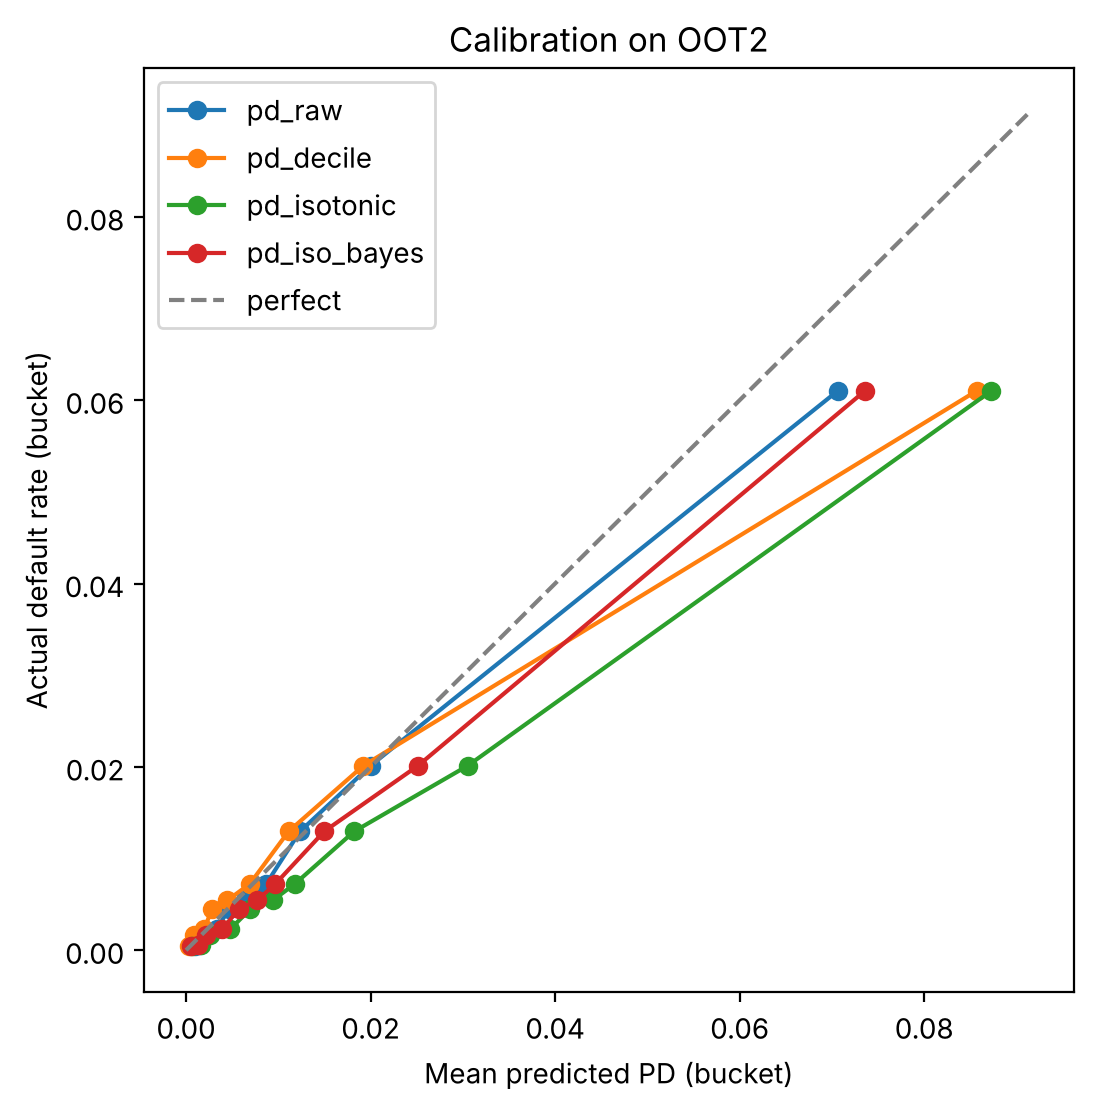

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
for m in METHODS:
    ax.plot(oot2_table[m], oot2_table['actual_rate'], marker='o', label=m)
top = max(oot2_table[METHODS].max().max(), oot2_table['actual_rate'].max()) * 1.05
ax.plot([0, top], [0, top], linestyle='--', color='grey', label='perfect')
ax.set_xlabel('Mean predicted PD (bucket)')
ax.set_ylabel('Actual default rate (bucket)')
ax.set_title('Calibration on OOT2')
ax.legend()
plt.show()

In [11]:
def binomial_test(df, pd_col, n=10):
    t = df.copy()
    t['bucket'] = pd.qcut(t['y_pred'].rank(method='first'), n, labels=False) + 1
    rows = []
    for b, g in t.groupby('bucket'):
        firms = len(g)
        defaults = int(g['y_true'].sum())
        p = g[pd_col].mean()
        low, high = binom.ppf(0.025, firms, p), binom.ppf(0.975, firms, p)
        p_lower = binom.cdf(defaults, firms, p)
        p_upper = binom.sf(defaults - 1, firms, p)
        rows.append({
            'bucket': b, 'firms': firms, 'mean_PD': p,
            'expected_def': firms * p, 'actual_def': defaults,
            'low_95': low, 'high_95': high,
            'p_value': min(1.0, 2 * min(p_lower, p_upper)),
            'pass': low <= defaults <= high,
        })
    return pd.DataFrame(rows).set_index('bucket')

pd.DataFrame({m: [binomial_test(oot2_scores, m)['pass'].sum()] for m in METHODS}, index=['buckets_pass'])

,pd_raw,pd_decile,pd_isotonic,pd_iso_bayes
buckets_pass,5,6,1,2


In [12]:
binomial_test(oot2_scores, 'pd_iso_bayes').round(4)

,firms,mean_PD,expected_def,actual_def,low_95,high_95,p_value,pass
bucket,,,,,,,,
1,18373,0.0006,10.3730,8,5.0,17.0,0.5847,True
2,18373,0.0013,23.9075,10,15.0,34.0,0.0023,False
3,18373,0.0021,39.4334,30,28.0,52.0,0.1454,True
4,18373,0.0039,71.8912,42,56.0,89.0,0.0002,False
5,18373,0.0057,104.6706,82,85.0,125.0,0.0251,False
6,18373,0.0077,141.6883,100,119.0,165.0,0.0003,False
7,18373,0.0097,177.8958,133,152.0,204.0,0.0005,False
8,18373,0.0150,274.9453,238,243.0,308.0,0.0241,False
9,18373,0.0252,462.0823,370,421.0,504.0,0.0000,False


In [13]:
SEGMENT_COLS = ['sector_category', 'legal_structure_category']
MIN_FIRMS = 200

for col in SEGMENT_COLS:
    seg = oot2_scores.groupby(col).agg(
        firms=('y_true', 'size'),
        actual_rate=('y_true', 'mean'),
        pd_raw=('pd_raw', 'mean'),
        pd_decile=('pd_decile', 'mean'),
        pd_iso_bayes=('pd_iso_bayes', 'mean'),
    )
    seg = seg[seg['firms'] >= MIN_FIRMS].sort_values('firms', ascending=False)
    seg['gap_iso_bayes'] = seg['pd_iso_bayes'] - seg['actual_rate']
    display(seg.round(4))

,firms,actual_rate,pd_raw,pd_decile,pd_iso_bayes,gap_iso_bayes
sector_category,,,,,,
68.0,36168,0.0077,0.0077,0.0075,0.0087,0.0011
41.0,25479,0.0131,0.0140,0.0149,0.0160,0.0029
46.0,20618,0.0145,0.0149,0.0157,0.0165,0.0021
25.0,8318,0.0103,0.0125,0.0117,0.0137,0.0033
47.0,7529,0.0151,0.0151,0.0153,0.0166,0.0014
28.0,5714,0.0105,0.0138,0.0136,0.0149,0.0043
43.0,5600,0.0157,0.0167,0.0176,0.0184,0.0027
45.0,4326,0.0155,0.0167,0.0155,0.0178,0.0023
70.0,4122,0.0124,0.0175,0.0189,0.0194,0.0070


,firms,actual_rate,pd_raw,pd_decile,pd_iso_bayes,gap_iso_bayes
legal_structure_category,,,,,,
SRL,133083,0.0111,0.0127,0.0131,0.0141,0.0031
SRU,28358,0.0170,0.0179,0.0187,0.0196,0.0025
SPA,17882,0.0082,0.0088,0.0082,0.0097,0.0015
SAU,4363,0.0076,0.0102,0.0105,0.0112,0.0036


In [14]:
raw_auc = roc_auc_score(oot2_scores['y_true'], oot2_scores['pd_raw'])
oot2_calib = calib_table(oot2_scores)
checks = []
for m in METHODS:
    p = oot2_scores[m].clip(1e-6, 1 - 1e-6)
    checks.append({
        'method': m,
        'level_gap': p.mean() - oot2_scores['y_true'].mean(),
        'buckets_pass': f"{binomial_test(oot2_scores, m)['pass'].sum()}/10",
        'Brier': brier_score_loss(oot2_scores['y_true'], p),
        'LogLoss': log_loss(oot2_scores['y_true'], p),
        'AUC_change': roc_auc_score(oot2_scores['y_true'], p) - raw_auc,
        'monotone': bool((oot2_calib[m].diff().dropna() >= 0).all()),
    })
pd.DataFrame(checks).set_index('method').round(5)

,level_gap,buckets_pass,Brier,LogLoss,AUC_change,monotone
method,,,,,,
pd_raw,0.00146,5/10,0.01085,0.05207,0.00000,True
pd_decile,0.00177,6/10,0.01123,0.05446,-0.01182,True
pd_isotonic,0.00577,1/10,0.01091,0.05341,-0.00036,True
pd_iso_bayes,0.00286,2/10,0.01083,0.05256,-0.00036,True


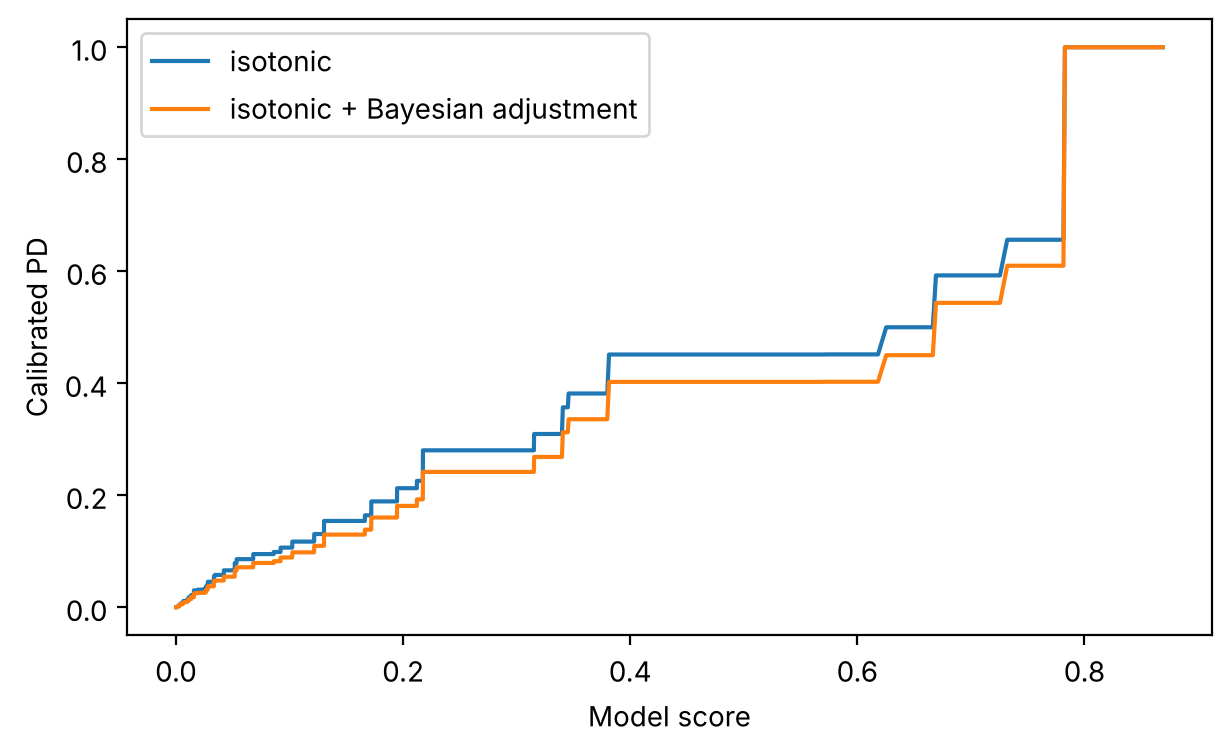

In [15]:
grid = pd.Series(np.sort(CALIB_SET['y_pred'].unique()))
plt.figure(figsize=(7, 4))
plt.plot(grid, isotonic_pd(grid), label='isotonic')
plt.plot(grid, calibrated_pd(grid), label='isotonic + Bayesian adjustment')
plt.xlabel('Model score')
plt.ylabel('Calibrated PD')
plt.legend()
plt.show()

In [16]:
oot1_scores.to_csv(f'../Model_scores/scores_oot1{MODEL}_calibration2.csv', index=False)
oot2_scores.to_csv(f'../Model_scores/scores_oot2{MODEL}_calibration2.csv', index=False)